# 03 重构残差与异常打分

本 Notebook 展示无监督异常检测的残差分析框架：

1. 加载预处理后的正常/异常窗口；
2. 加载训练好的模型（不存在时回退到快速 PCA 基线）；
3. 可视化输入、重构和平方残差；
4. 用正常数据校准空间归一化与阈值；
5. 绘制样本级异常评分、通道级定位曲线和多趟融合结果。


In [1]:
%matplotlib inline

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import yaml

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import (
    AnomalyScorer,
    MultiPassAccumulator,
    reconstruction_residual,
    select_threshold,
)
from src.models import PCABaseline, build_model
from src.utils import plot_heatmap, plot_sample_scores, plot_score_profile

config = yaml.safe_load(
    (PROJECT_ROOT / "configs" / "exp_default.yaml").read_text(encoding="utf-8")
)
DATA_DIR = PROJECT_ROOT / "data"


## 1. 加载预处理窗口


In [2]:
def load_windows(split):
    root = DATA_DIR / "processed" / split
    files = sorted(root.rglob("*.npz"))
    if not files:
        raise FileNotFoundError(
            f"{root} 中没有窗口，请先运行 scripts/run_preprocess.py --synthetic --overwrite"
        )
    data, labels, flags, sources = [], [], [], []
    sampling_rate_hz, channel_spacing_m = 1000.0, 0.5
    has_labels = False
    for path in files:
        with np.load(path, allow_pickle=False) as payload:
            window = np.asarray(payload["data"], dtype=np.float32)
            label = (
                np.asarray(payload["channel_labels"], dtype=np.uint8).reshape(-1)
                if "channel_labels" in payload
                else np.zeros(window.shape[0], dtype=np.uint8)
            )
            file_has_labels = (
                bool(payload["has_labels"][0]) if "has_labels" in payload else False
            )
            has_labels = has_labels or file_has_labels or bool(label.any())
            flags.append(
                int(payload["is_anomaly"][0])
                if "is_anomaly" in payload
                else int(label.any())
            )
            sources.append(
                str(payload["source"][0]) if "source" in payload else path.parent.name
            )
            data.append(window)
            labels.append(label)
            if "sampling_rate_hz" in payload:
                sampling_rate_hz = float(payload["sampling_rate_hz"][0])
            if "channel_spacing_m" in payload:
                channel_spacing_m = float(payload["channel_spacing_m"][0])
    return {
        "data": np.stack(data),
        "channel_labels": np.stack(labels),
        "sample_labels": np.asarray(flags, dtype=np.int64),
        "sources": np.asarray(sources),
        "has_labels": has_labels,
        "sampling_rate_hz": sampling_rate_hz,
        "channel_spacing_m": channel_spacing_m,
    }


train = load_windows("train")
test = load_windows("test")
normal_mask = train["sample_labels"] == 0
if not normal_mask.any():
    raise RuntimeError("训练集中没有正常样本")
normal_train = train["data"][normal_mask]
print("Train:", train["data"].shape, "Test:", test["data"].shape)
print("Test anomalies:", int(test["sample_labels"].sum()), "/", len(test["data"]))


Train: (304, 96, 128) Test: (458, 96, 128)
Test anomalies: 304 / 458


## 2. 加载模型（若未训练则使用 PCA 演示）


In [3]:
model = None
model_label = None
model_name = str(config["model"]["name"])
checkpoint_dir = PROJECT_ROOT / config["paths"]["checkpoint_dir"]
checkpoint_candidates = [
    checkpoint_dir / f"{model_name}{suffix}" for suffix in (".pt", ".pth", ".pkl")
]
checkpoint = next((path for path in checkpoint_candidates if path.is_file()), None)

if checkpoint is not None:
    metadata_path = checkpoint.with_name(f"{checkpoint.stem}_metadata.json")
    checkpoint_metadata = (
        json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata_path.is_file()
        else {}
    )
    model_label = str(checkpoint_metadata.get("model_name", model_name))
    try:
        prototype = build_model(
            model_label,
            model_params=checkpoint_metadata.get(
                "model_params", config["model"]["params"].get(model_label, {})
            ),
            training_config=config["training"],
        )
        model = type(prototype).load(checkpoint)
        print("Loaded checkpoint:", checkpoint)
    except Exception as exc:  # notebook-friendly fallback
        print("Checkpoint loading failed, using PCA:", exc)

if model is None:
    n_components = min(8, normal_train.shape[0], normal_train.shape[1] * normal_train.shape[2])
    model = PCABaseline(n_components=max(1, n_components))
    model.fit(normal_train[: min(256, len(normal_train))])
    model_label = "PCA fallback"
print("Active model:", model_label)


Active model: PCA fallback


## 3. 校准异常打分

在正常训练样本上拟合逐通道稳健归一化，并按第 99 百分位确定阈值。


In [4]:
scorer = AnomalyScorer(
    model,
    topk_channels=int(config["evaluation"]["topk_channels"]),
    aggregation="topk",
    normalization="robust",
    sampling_rate_hz=train["sampling_rate_hz"],
)
scorer.fit(normal_train)
normal_scores = scorer.sample_scores(normal_train)
threshold = select_threshold(
    normal_scores,
    method="percentile",
    percentile=float(config["evaluation"]["threshold_percentile"]),
)
result = scorer.score(test["data"])
print(f"Calibration threshold: {threshold:.4f}")
print(f"Score range: [{result.sample_scores.min():.3f}, {result.sample_scores.max():.3f}]")


Calibration threshold: 13.3476
Score range: [2.618, 26.941]


## 4. 重构残差可视化


Sample index: 35
True anomaly channels: [3, 4, 5, 6, 7, 8]


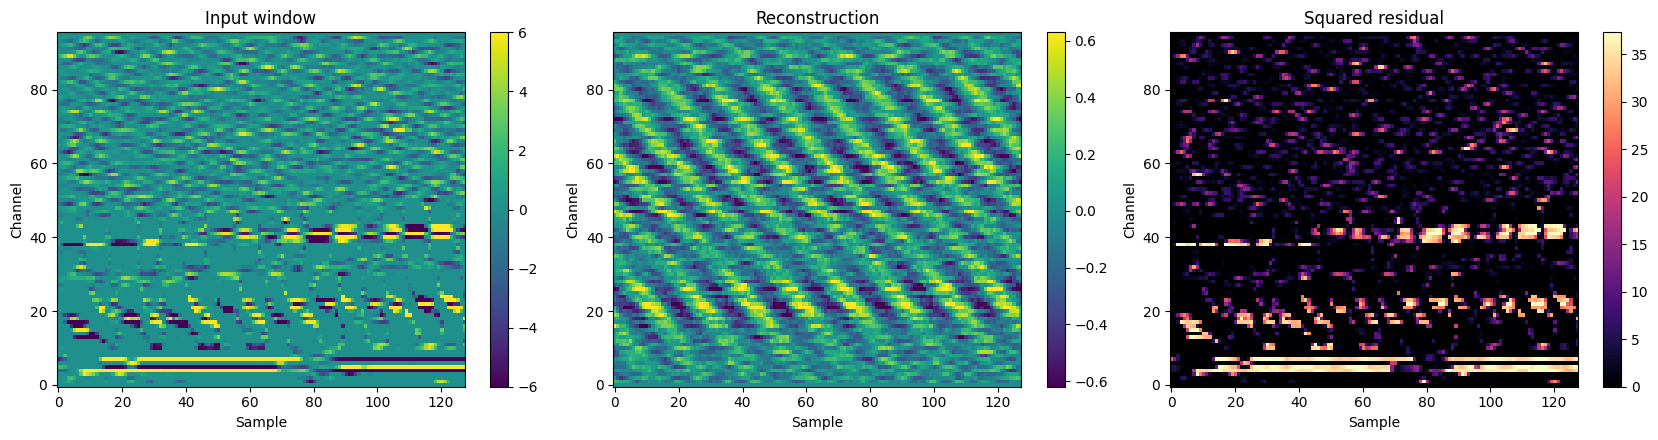

In [5]:
if test["has_labels"] and (test["sample_labels"] == 1).any():
    candidates = np.flatnonzero(test["sample_labels"] == 1)
    sample_index = int(candidates[np.argmax(result.sample_scores[candidates])])
else:
    sample_index = int(np.argmax(result.sample_scores))

sample = test["data"][sample_index]
try:
    reconstruction = model.reconstruct(sample[None, ...])[0]
except NotImplementedError:
    print("当前模型不支持 reconstruction，改用 PCA 展示残差。")
    residual_model = PCABaseline(n_components=min(8, len(normal_train)))
    residual_model.fit(normal_train)
    reconstruction = residual_model.reconstruct(sample[None, ...])[0]

residual_map = reconstruction_residual(
    sample[None, ...], reconstruction[None, ...], reduction="none"
)[0]
true_channels = np.flatnonzero(test["channel_labels"][sample_index])
print("Sample index:", sample_index)
print("True anomaly channels:", true_channels.tolist())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_heatmap(sample, ax=axes[0], title="Input window", xlabel="Sample", ylabel="Channel")
plot_heatmap(reconstruction, ax=axes[1], title="Reconstruction", xlabel="Sample", ylabel="Channel")
plot_heatmap(residual_map, ax=axes[2], title="Squared residual", xlabel="Sample", ylabel="Channel", cmap="magma")
plt.tight_layout()
plt.show()


## 5. 异常评分与通道定位


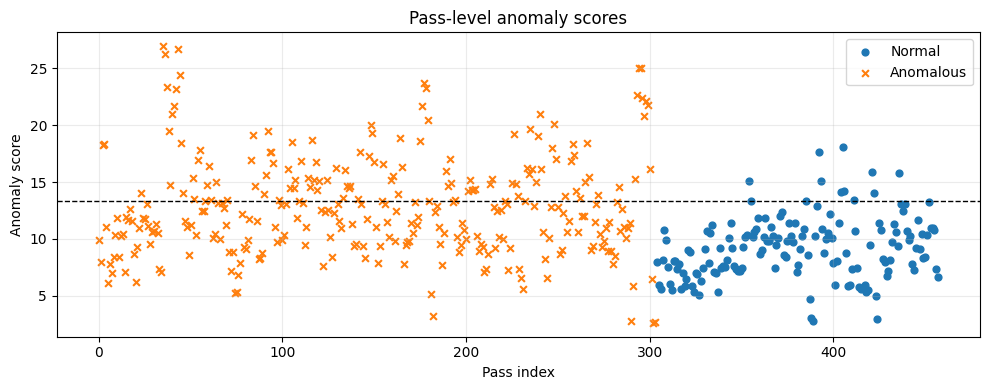

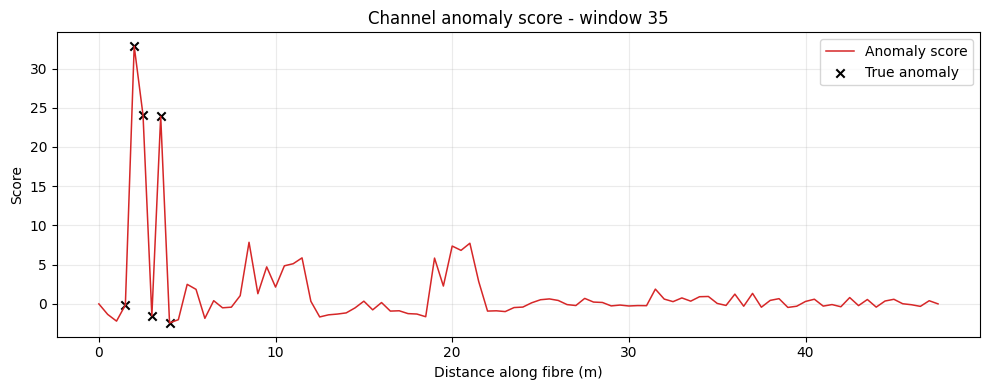

In [6]:
labels = test["sample_labels"] if test["has_labels"] else None
fig, ax = plot_sample_scores(
    result.sample_scores,
    labels=labels,
    threshold=threshold,
    title="Pass-level anomaly scores",
)
plt.show()

distance_m = np.arange(test["data"].shape[1]) * test["channel_spacing_m"]
fig, ax = plot_score_profile(
    result.channel_scores[sample_index],
    positions_m=distance_m,
    title=f"Channel anomaly score - window {sample_index}",
)
if true_channels.size:
    ax.scatter(
        true_channels * test["channel_spacing_m"],
        result.channel_scores[sample_index, true_channels],
        color="black",
        marker="x",
        label="True anomaly",
    )
    ax.legend(loc="best")
plt.show()


## 6. 多趟累积

将同一来源、重复通过的各窗口通道分数做稳健融合，可降低单趟激励变化带来的
波动。`mean`、`median`、`max` 可通过配置或构造参数切换。


Fused sessions: 16


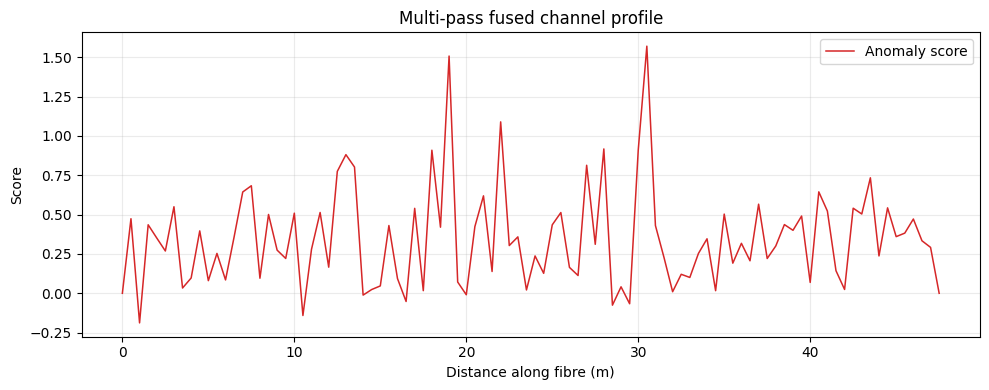

In [7]:
accumulator = MultiPassAccumulator(
    method=config["evaluation"].get("aggregate_method", "median")
)
for source in np.unique(test["sources"]):
    source_mask = test["sources"] == source
    profile = result.channel_scores[source_mask].mean(axis=0)
    accumulator.add(profile, pass_id=str(source))
fused = accumulator.fuse()
print("Fused sessions:", int(fused["n_passes"][0]))

fig, ax = plot_score_profile(
    fused["profile"],
    positions_m=distance_m,
    title="Multi-pass fused channel profile",
)
plt.show()


## 小结

- 异常打分流程：模型重构/通道评分 → 空间稳健归一化 → top-k 聚合 → 阈值判定。
- 定位误差可用 `src.evaluation.metrics.compute_localization_error` 定量评估。
- 修改 `configs/exp_default.yaml` 中的 `model.name` 后重新训练，即可在同一框架
  下比较 PCA、孤立森林和各神经网络模型。
